In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping
from scipy.stats import uniform, randint

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


In [2]:
# Загрузка
df = pd.read_csv('diabetes.csv')
print("Датасет о диабете")
print("="*50)
print(f"Размер: {df.shape}")

# Разделение на признаки и целевую переменную
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

# Нормализация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Разделение на train/val/test (70/15/15)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"\nРазмеры выборок:")
print(f"Train: {X_train.shape}, {np.bincount(y_train)}")
print(f"Val:   {X_val.shape}, {np.bincount(y_val)}")
print(f"Test:  {X_test.shape}, {np.bincount(y_test)}")

Датасет о диабете
Размер: (768, 9)

Размеры выборок:
Train: (537, 8), [350 187]
Val:   (115, 8), [75 40]
Test:  (116, 8), [75 41]


Базовая модель (без регуляризации):


C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,521 (170.00 KB)

 Trainable params: 43,521 (170.00 KB)

 Non-trainable params: 0 (0.00 B)

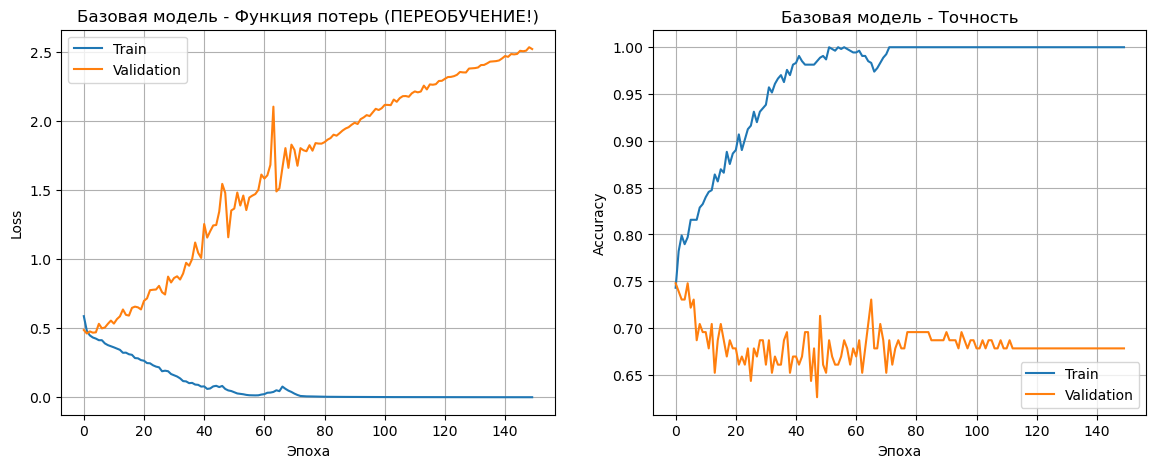


Базовая модель на тесте: Accuracy = 0.6897


In [3]:
def create_baseline_model():
    """Базовая модель БЕЗ регуляризации (с большим количеством нейронов для переобучения)"""
    model = Sequential(name="baseline")
    model.add(Dense(256, input_dim=8, activation='relu'))  # Много нейронов
    model.add(Dense(128, activation='relu'))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Создаем и обучаем базовую модель
baseline_model = create_baseline_model()
print("Базовая модель (без регуляризации):")
baseline_model.summary()

# Обучаем без early stopping чтобы увидеть переобучение
history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)

# Графики для базовой модели
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['loss'], label='Train')
plt.plot(history_baseline.history['val_loss'], label='Validation')
plt.title('Базовая модель - Функция потерь (ПЕРЕОБУЧЕНИЕ!)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history['accuracy'], label='Train')
plt.plot(history_baseline.history['val_accuracy'], label='Validation')
plt.title('Базовая модель - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

# Оценка на тесте
baseline_loss, baseline_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
print(f"\nБазовая модель на тесте: Accuracy = {baseline_acc:.4f}")

Модель с L2-регуляризацией (λ=0.01):


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,521 (170.00 KB)

 Trainable params: 43,521 (170.00 KB)

 Non-trainable params: 0 (0.00 B)

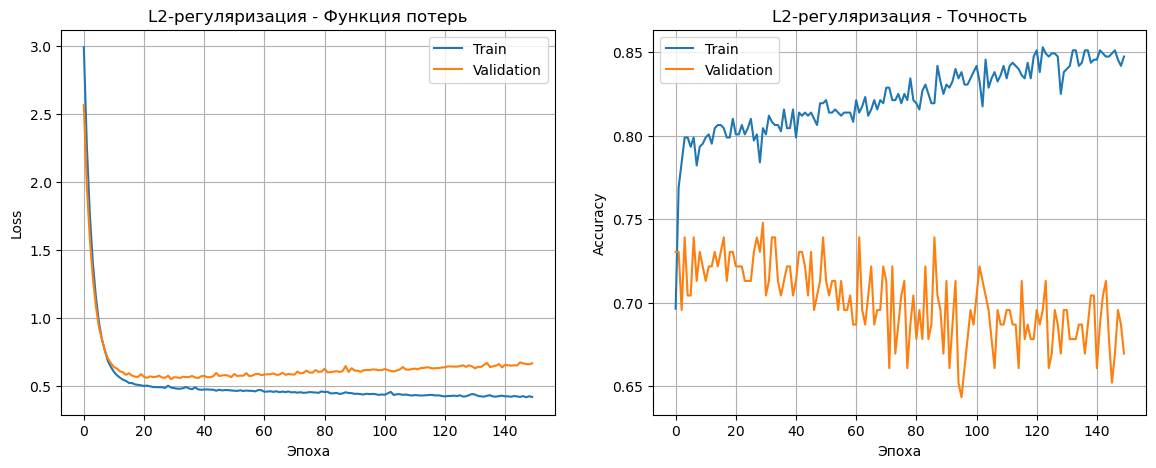


L2 модель на тесте: Accuracy = 0.7586


In [4]:
# Ячейка 4: Модель с L2-регуляризацией
print("Модель с L2-регуляризацией (λ=0.01):")

# Создаем модель без регуляризации в имени
model_l2 = Sequential()
model_l2.add(Dense(256, input_dim=8, activation='relu', kernel_regularizer=l2(0.01)))
model_l2.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
model_l2.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
model_l2.add(Dense(1, activation='sigmoid'))

model_l2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_l2.summary()

# Обучаем
history_l2 = model_l2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_l2.history['loss'], label='Train')
plt.plot(history_l2.history['val_loss'], label='Validation')
plt.title('L2-регуляризация - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_l2.history['accuracy'], label='Train')
plt.plot(history_l2.history['val_accuracy'], label='Validation')
plt.title('L2-регуляризация - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

# Оценка
l2_loss, l2_acc = model_l2.evaluate(X_test, y_test, verbose=0)
print(f"\nL2 модель на тесте: Accuracy = {l2_acc:.4f}")


Модель с Dropout (rate=0.3):


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,521 (170.00 KB)

 Trainable params: 43,521 (170.00 KB)

 Non-trainable params: 0 (0.00 B)

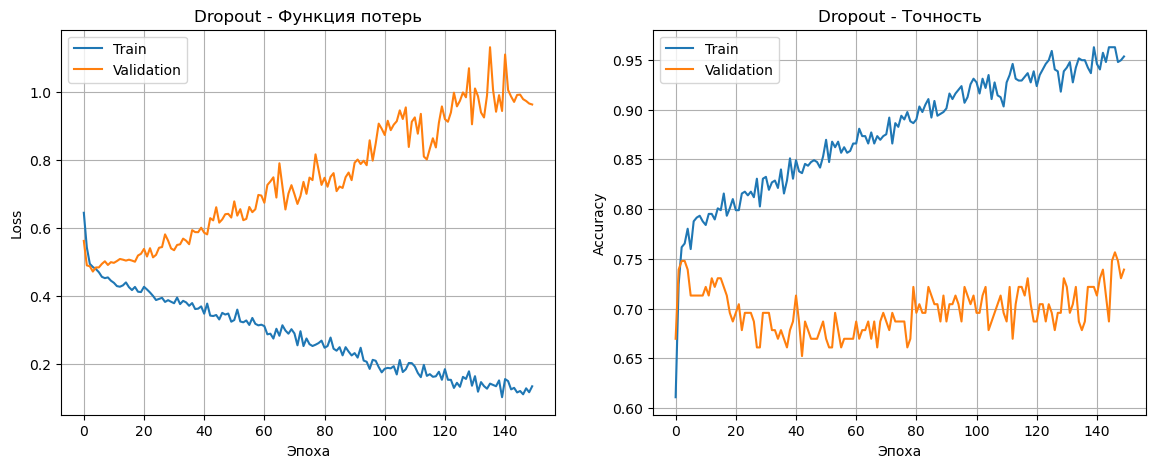


Dropout модель на тесте: Accuracy = 0.7155


In [5]:
print("\n" + "="*60)
print("Модель с Dropout (rate=0.3):")

dropout_model = Sequential()
dropout_model.add(Dense(256, input_dim=8, activation='relu'))
dropout_model.add(Dropout(0.3))
dropout_model.add(Dense(128, activation='relu'))
dropout_model.add(Dropout(0.3))
dropout_model.add(Dense(64, activation='relu'))
dropout_model.add(Dropout(0.3))
dropout_model.add(Dense(1, activation='sigmoid'))

dropout_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

dropout_model.summary()

history_dropout = dropout_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_dropout.history['loss'], label='Train')
plt.plot(history_dropout.history['val_loss'], label='Validation')
plt.title('Dropout - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_dropout.history['accuracy'], label='Train')
plt.plot(history_dropout.history['val_accuracy'], label='Validation')
plt.title('Dropout - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

dropout_loss, dropout_acc = dropout_model.evaluate(X_test, y_test, verbose=0)
print(f"\nDropout модель на тесте: Accuracy = {dropout_acc:.4f}")


Модель с Batch Normalization:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,313 (177.00 KB)

 Trainable params: 44,417 (173.50 KB)

 Non-trainable params: 896 (3.50 KB)

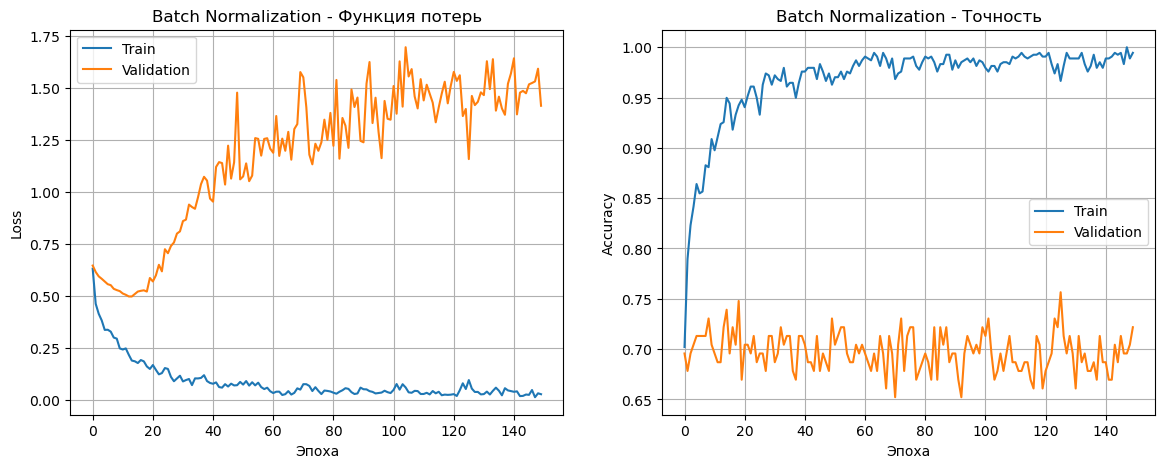


BatchNorm модель на тесте: Accuracy = 0.6810


In [6]:
print("\n" + "="*60)
print("Модель с Batch Normalization:")

bn_model = Sequential()
bn_model.add(Dense(256, input_dim=8, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(128, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(64, activation='relu'))
bn_model.add(BatchNormalization())
bn_model.add(Dense(1, activation='sigmoid'))

bn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

bn_model.summary()

history_bn = bn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_bn.history['loss'], label='Train')
plt.plot(history_bn.history['val_loss'], label='Validation')
plt.title('Batch Normalization - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_bn.history['accuracy'], label='Train')
plt.plot(history_bn.history['val_accuracy'], label='Validation')
plt.title('Batch Normalization - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

bn_loss, bn_acc = bn_model.evaluate(X_test, y_test, verbose=0)
print(f"\nBatchNorm модель на тесте: Accuracy = {bn_acc:.4f}")


Модель с Early Stopping:
Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 2.
Обучение остановлено на эпохе 22


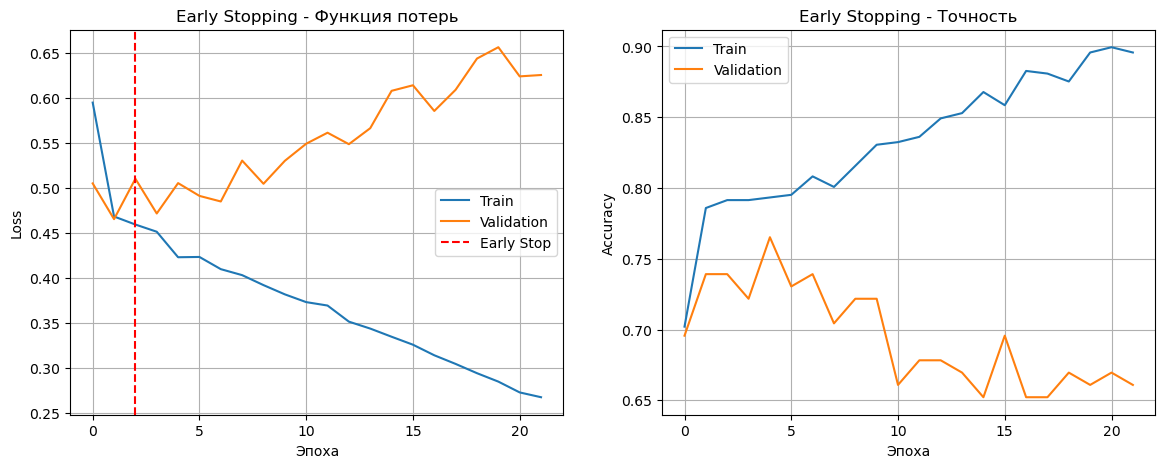


Early Stopping модель на тесте: Accuracy = 0.7414


In [7]:
print("\n" + "="*60)
print("Модель с Early Stopping:")

es_model = Sequential()
es_model.add(Dense(256, input_dim=8, activation='relu'))
es_model.add(Dense(128, activation='relu'))
es_model.add(Dense(64, activation='relu'))
es_model.add(Dense(1, activation='sigmoid'))

es_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_es = es_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

print(f"Обучение остановлено на эпохе {len(history_es.history['loss'])}")

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_es.history['loss'], label='Train')
plt.plot(history_es.history['val_loss'], label='Validation')
plt.axvline(x=len(history_es.history['loss'])-20, color='red', linestyle='--', label='Early Stop')
plt.title('Early Stopping - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_es.history['accuracy'], label='Train')
plt.plot(history_es.history['val_accuracy'], label='Validation')
plt.title('Early Stopping - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

es_loss, es_acc = es_model.evaluate(X_test, y_test, verbose=0)
print(f"\nEarly Stopping модель на тесте: Accuracy = {es_acc:.4f}")


СРАВНЕНИЕ МЕТОДОВ БОРЬБЫ С ПЕРЕОБУЧЕНИЕМ
           Метод  Test Accuracy
0             L2       0.758621
1        Dropout       0.715517
2      BatchNorm       0.681035
3  EarlyStopping       0.741379



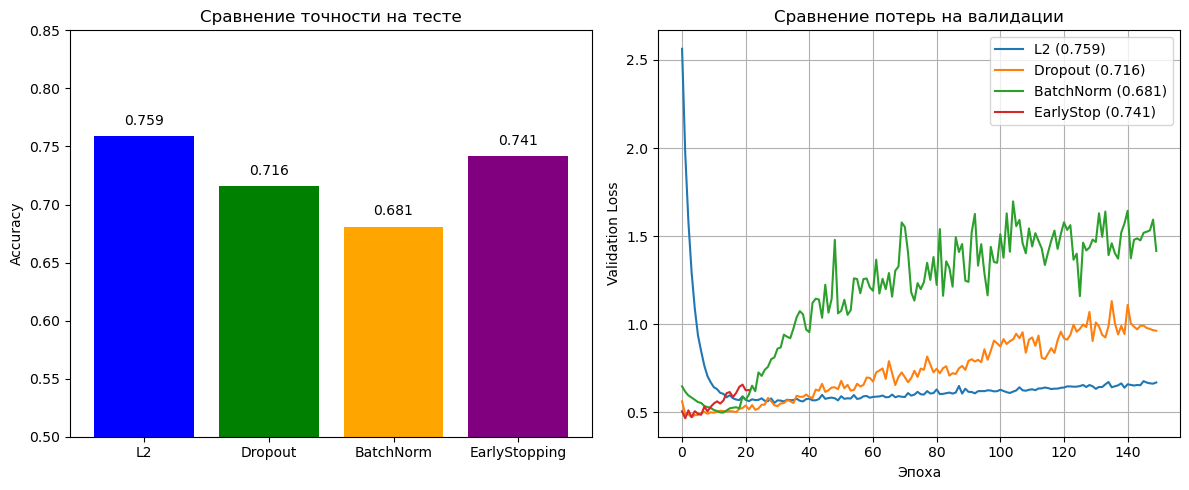

In [8]:
print("\n" + "="*60)
print("СРАВНЕНИЕ МЕТОДОВ БОРЬБЫ С ПЕРЕОБУЧЕНИЕМ")
print("="*60)

# Собираем результаты
results = pd.DataFrame({
    'Метод': ['L2', 'Dropout', 'BatchNorm', 'EarlyStopping'],
    'Test Accuracy': [l2_acc, dropout_acc, bn_acc, es_acc]
})

print(results)
print()

# График сравнения
plt.figure(figsize=(12, 5))

# Сравнение точности
plt.subplot(1, 2, 1)
bars = plt.bar(results['Метод'], results['Test Accuracy'], 
               color=['blue', 'green', 'orange', 'purple'])
plt.title('Сравнение точности на тесте')
plt.ylabel('Accuracy')
plt.ylim(0.5, 0.85)
for bar, acc in zip(bars, results['Test Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc:.3f}', ha='center')

# Сравнение кривых обучения
plt.subplot(1, 2, 2)
plt.plot(history_l2.history['val_loss'], label=f'L2 ({l2_acc:.3f})')
plt.plot(history_dropout.history['val_loss'], label=f'Dropout ({dropout_acc:.3f})')
plt.plot(history_bn.history['val_loss'], label=f'BatchNorm ({bn_acc:.3f})')
plt.plot(history_es.history['val_loss'], label=f'EarlyStop ({es_acc:.3f})')
plt.title('Сравнение потерь на валидации')
plt.xlabel('Эпоха')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


K-FOLD CROSS VALIDATION (5 ФОЛДОВ)

Fold 1/5


C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Лучшая точность: 0.7662

Fold 2/5
  Лучшая точность: 0.8247

Fold 3/5
  Лучшая точность: 0.7792

Fold 4/5
  Лучшая точность: 0.7843

Fold 5/5
  Лучшая точность: 0.7516

РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ:
  Средняя точность: 0.7812
  Стандартное отклонение: 0.0245
  Разброс: 0.7516 - 0.8247


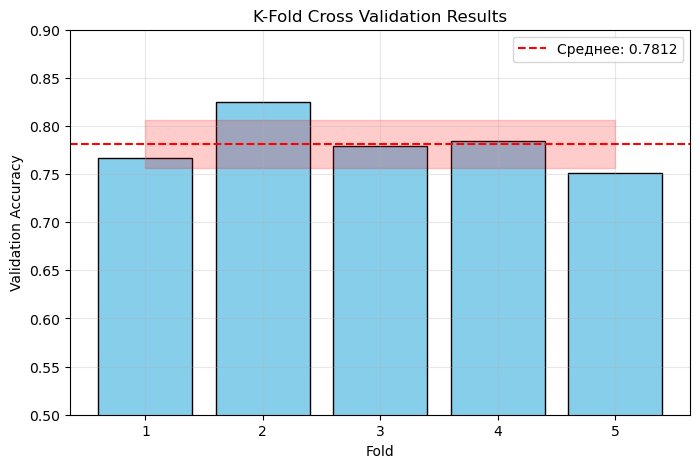

In [9]:
print("\n" + "="*60)
print("K-FOLD CROSS VALIDATION (5 ФОЛДОВ)")
print("="*60)

def create_cv_model():
    """Модель для кросс-валидации"""
    model = Sequential()
    model.add(Dense(128, input_dim=8, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# K-Fold
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_scaled, y)):
    print(f"\nFold {fold + 1}/5")
    
    # Разделяем данные
    X_fold_train = X_scaled[train_idx]
    y_fold_train = y[train_idx]
    X_fold_val = X_scaled[val_idx]
    y_fold_val = y[val_idx]
    
    # Создаем и обучаем модель
    model = create_cv_model()
    history = model.fit(
        X_fold_train, y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=50,
        batch_size=32,
        verbose=0
    )
    
    # Лучшая точность на валидации
    val_acc = max(history.history['val_accuracy'])
    cv_scores.append(val_acc)
    print(f"  Лучшая точность: {val_acc:.4f}")

print(f"\nРЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ:")
print(f"  Средняя точность: {np.mean(cv_scores):.4f}")
print(f"  Стандартное отклонение: {np.std(cv_scores):.4f}")
print(f"  Разброс: {np.min(cv_scores):.4f} - {np.max(cv_scores):.4f}")

# Визуализация
plt.figure(figsize=(8, 5))
plt.bar(range(1, 6), cv_scores, color='skyblue', edgecolor='black')
plt.axhline(y=np.mean(cv_scores), color='red', linestyle='--', 
            label=f'Среднее: {np.mean(cv_scores):.4f}')
plt.fill_between(range(1, 6), 
                 np.mean(cv_scores) - np.std(cv_scores), 
                 np.mean(cv_scores) + np.std(cv_scores), 
                 alpha=0.2, color='red')
plt.title('K-Fold Cross Validation Results')
plt.xlabel('Fold')
plt.ylabel('Validation Accuracy')
plt.ylim(0.5, 0.9)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
print("\n" + "="*60)
print("ПОДБОР ГИПЕРПАРАМЕТРОВ (RANDOMIZED SEARCH)")
print("="*60)

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Для новых версий TensorFlow используем другой импорт
# Устанавливаем scikeras если нужно
import sys
!{sys.executable} -m pip install scikeras

from scikeras.wrappers import KerasClassifier

def create_model_for_search(learning_rate=0.001, dropout_rate=0.3, units_1=128, units_2=64):
    """Модель для поиска гиперпараметров"""
    model = Sequential()
    model.add(Dense(units_1, input_dim=8, activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(units_2, activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Оборачиваем модель
model_wrapper = KerasClassifier(
    model=create_model_for_search,  # В scikeras используется model вместо build_fn
    learning_rate=0.001,
    dropout_rate=0.3,
    units_1=128,
    units_2=64,
    epochs=30,
    batch_size=32,
    verbose=0
)

# Пространство гиперпараметров
param_dist = {
    'learning_rate': uniform(0.0001, 0.01),
    'dropout_rate': uniform(0.1, 0.5),
    'units_1': randint(64, 256),
    'units_2': randint(32, 128)
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=model_wrapper,
    param_distributions=param_dist,
    n_iter=10,  # 10 случайных комбинаций
    cv=3,
    scoring='accuracy',
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Поиск гиперпараметров запущен... (это может занять несколько минут)")

# Запускаем поиск
search_result = random_search.fit(X_scaled, y)

print(f"\nЛУЧШИЕ ПАРАМЕТРЫ:")
for param, value in search_result.best_params_.items():
    print(f"  {param}: {value}")
print(f"Лучшая точность: {search_result.best_score_:.4f}")


ПОДБОР ГИПЕРПАРАМЕТРОВ (RANDOMIZED SEARCH)


Defaulting to user installation because normal site-packages is not writeable
Поиск гиперпараметров запущен... (это может занять несколько минут)
Fitting 3 folds for each of 10 candidates, totalling 30 fits


C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



ЛУЧШИЕ ПАРАМЕТРЫ:
  dropout_rate: 0.3993292420985183
  learning_rate: 0.0016601864044243652
  units_1: 138
  units_2: 106
Лучшая точность: 0.7773



ФИНАЛЬНАЯ МОДЕЛЬ С ЛУЧШИМИ ПАРАМЕТРАМИ
Параметры: {'dropout_rate': 0.3993292420985183, 'learning_rate': 0.0016601864044243652, 'units_1': 138, 'units_2': 106}


C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_38 (Dense)                │ (None, 138)            │         1,242 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 138)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 106)            │        14,734 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 106)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 1)              │           107 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,083 (62.82 KB)

 Trainable params: 16,083 (62.82 KB)

 Non-trainable params: 0 (0.00 B)


Финальная модель на тесте: Accuracy = 0.7672


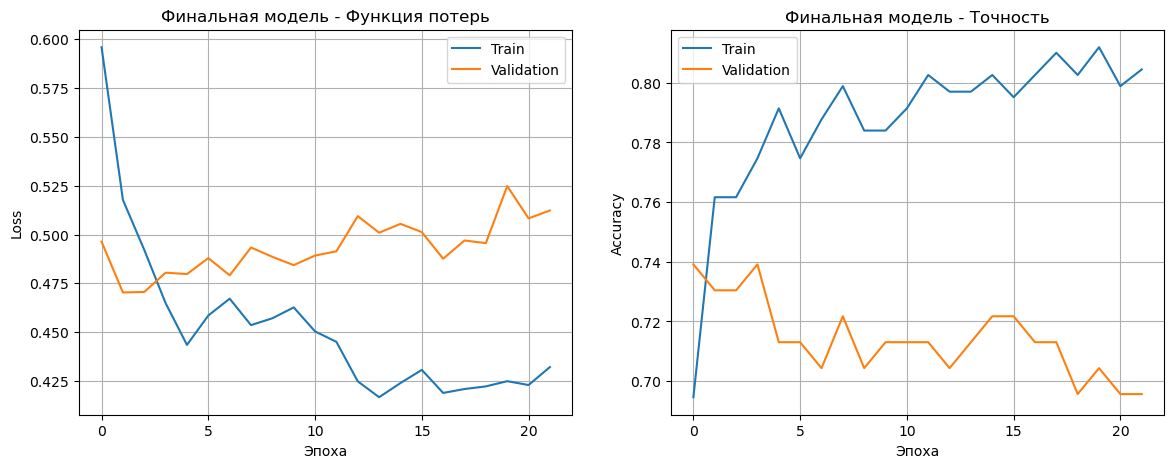

In [12]:
print("\n" + "="*60)
print("ФИНАЛЬНАЯ МОДЕЛЬ С ЛУЧШИМИ ПАРАМЕТРАМИ")
print("="*60)

best_params = search_result.best_params_
print(f"Параметры: {best_params}")

final_model = Sequential()
final_model.add(Dense(int(best_params['units_1']), input_dim=8, activation='relu'))
final_model.add(Dropout(best_params['dropout_rate']))
final_model.add(Dense(int(best_params['units_2']), activation='relu'))
final_model.add(Dropout(best_params['dropout_rate']))
final_model.add(Dense(1, activation='sigmoid'))

final_model.compile(
    optimizer=Adam(learning_rate=best_params['learning_rate']),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

final_model.summary()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history_final = final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

# Оценка
final_loss, final_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"\nФинальная модель на тесте: Accuracy = {final_acc:.4f}")

# Графики
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_final.history['loss'], label='Train')
plt.plot(history_final.history['val_loss'], label='Validation')
plt.title('Финальная модель - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_final.history['accuracy'], label='Train')
plt.plot(history_final.history['val_accuracy'], label='Validation')
plt.title('Финальная модель - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()


МАТРИЦА ОШИБОК И ОТЧЕТ ПО КЛАССИФИКАЦИИ


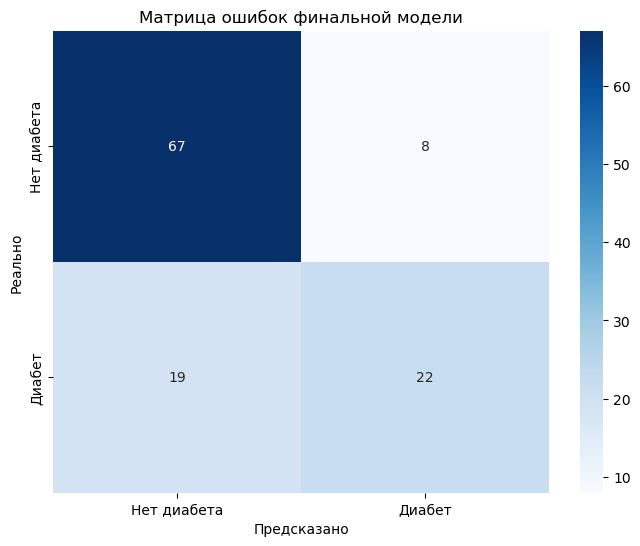


ОТЧЕТ ПО КЛАССИФИКАЦИИ:
              precision    recall  f1-score   support

 Нет диабета       0.78      0.89      0.83        75
      Диабет       0.73      0.54      0.62        41

    accuracy                           0.77       116
   macro avg       0.76      0.71      0.73       116
weighted avg       0.76      0.77      0.76       116


ИТОГОВОЕ СРАВНЕНИЕ
         Метод  Test Accuracy
0           L2       0.758621
1      Dropout       0.715517
2    BatchNorm       0.681035
3    EarlyStop       0.741379
4  Best Params       0.767241


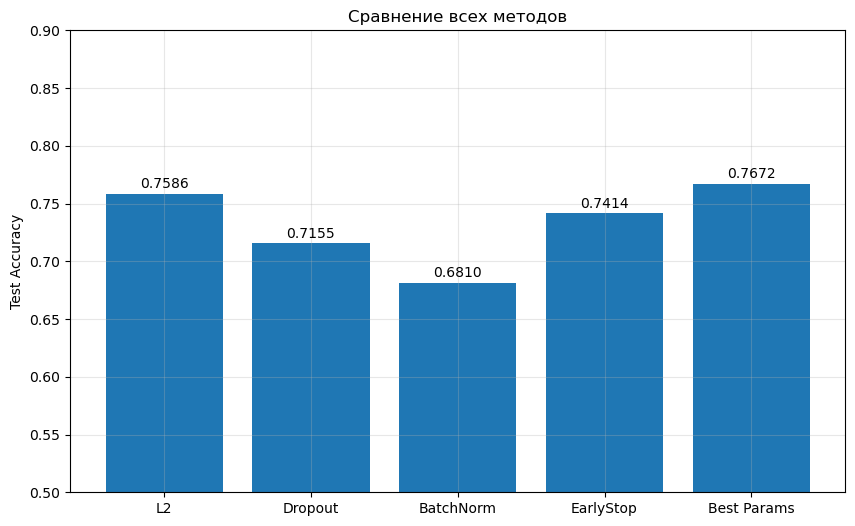

In [13]:
print("\n" + "="*60)
print("МАТРИЦА ОШИБОК И ОТЧЕТ ПО КЛАССИФИКАЦИИ")
print("="*60)

# Предсказания
y_pred_prob = final_model.predict(X_test, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Нет диабета', 'Диабет'],
            yticklabels=['Нет диабета', 'Диабет'])
plt.title('Матрица ошибок финальной модели')
plt.xlabel('Предсказано')
plt.ylabel('Реально')
plt.show()

# Отчет
print("\nОТЧЕТ ПО КЛАССИФИКАЦИИ:")
print(classification_report(y_test, y_pred, target_names=['Нет диабета', 'Диабет']))

# Итоговое сравнение
print("\n" + "="*60)
print("ИТОГОВОЕ СРАВНЕНИЕ")
print("="*60)

final_results = pd.DataFrame({
    'Метод': ['L2', 'Dropout', 'BatchNorm', 'EarlyStop', 'Best Params'],
    'Test Accuracy': [l2_acc, dropout_acc, bn_acc, es_acc, final_acc]
})
print(final_results)

plt.figure(figsize=(10, 6))
bars = plt.bar(final_results['Метод'], final_results['Test Accuracy'])
plt.title('Сравнение всех методов')
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 0.9)
for bar, acc in zip(bars, final_results['Test Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
             f'{acc:.4f}', ha='center')
plt.grid(True, alpha=0.3)
plt.show()